In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
data=pd.read_csv('diabetes.csv')

In [4]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


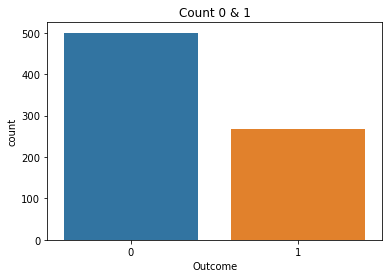

In [8]:
import seaborn as sns
sns.countplot(x='Outcome',data=data)
plt.title("Count 0 & 1")
plt.show()

In [9]:
print('Data Shape',data.shape)
print(data.info()) 
describe = data.describe()
describe.T

Data Shape (768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [10]:
from sklearn.tree import DecisionTreeClassifier
DTC = DecisionTreeClassifier()

In [11]:
from sklearn.model_selection import train_test_split

X = data.drop('Outcome', axis=1)
y = data.Outcome

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [12]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

def print_score(clf, X_train, y_train, X_test, y_test, train=True):
    if train:
        pred = clf.predict(X_train)
        clf_report = pd.DataFrame(classification_report(y_train, pred, output_dict=True))
        print("Train Result:")
        print(f"Accuracy Score: {accuracy_score(y_train, pred) * 100:.2f}%")
        print()
        print(f"CLASSIFICATION REPORT:\n{clf_report}")
        print()
        print(f"Confusion Matrix: \n {confusion_matrix(y_train, pred)}\n")
        
    elif train==False:
        pred = clf.predict(X_test)
        clf_report = pd.DataFrame(classification_report(y_test, pred, output_dict=True))
        print("Test Result:")        
        print(f"Accuracy Score: {accuracy_score(y_test, pred) * 100:.2f}%")
        print()
        print(f"CLASSIFICATION REPORT:\n{clf_report}")
        print()
        print(f"Confusion Matrix: \n {confusion_matrix(y_test, pred)}\n")

In [13]:
from sklearn.tree import DecisionTreeClassifier

tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)

print_score(tree_clf, X_train, y_train, X_test, y_test, train=True)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=False)

Train Result:
Accuracy Score: 100.00%

CLASSIFICATION REPORT:
               0      1  accuracy  macro avg  weighted avg
precision    1.0    1.0       1.0        1.0           1.0
recall       1.0    1.0       1.0        1.0           1.0
f1-score     1.0    1.0       1.0        1.0           1.0
support    349.0  188.0       1.0      537.0         537.0

Confusion Matrix: 
 [[349   0]
 [  0 188]]

Test Result:
Accuracy Score: 70.13%

CLASSIFICATION REPORT:
                    0          1  accuracy   macro avg  weighted avg
precision    0.810606   0.555556  0.701299    0.683081      0.722277
recall       0.708609   0.687500  0.701299    0.698055      0.701299
f1-score     0.756184   0.614525  0.701299    0.685354      0.707124
support    151.000000  80.000000  0.701299  231.000000    231.000000

Confusion Matrix: 
 [[107  44]
 [ 25  55]]



In [26]:
from sklearn.model_selection import cross_val_score
accuraccies = cross_val_score(estimator = DTC, X= X_train, y=y_train, cv=150)
print("Average Accuracies: ",np.mean(accuraccies))
print("Standart Deviation Accuracies: ",np.std(accuraccies))

SyntaxError: invalid syntax (<ipython-input-26-99f689255c75>, line 7)

ValueError: x and y must have same first dimension, but have shapes (1,) and (2,)

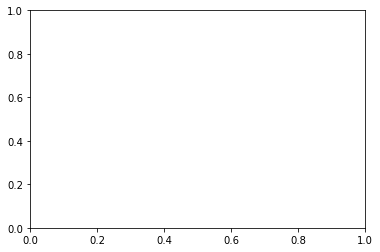

In [35]:
from sklearn.model_selection import cross_val_score
for i in range (150): 
    accuraccies = cross_val_score(estimator = DTC, X= X_train, y=y_train, cv=2)
    fig, ax = plt.subplots()
    plt.plot(i, accuraccies)
    i=i+30

In [18]:
DTC.fit(X_train,y_train) #learning
#prediciton
print("Decision Tree Score: ",DTC.score(X_test,y_test))
DTCscore = DTC.score(X_test,y_test)

Decision Tree Score:  0.7012987012987013
